# Course 10: Deep Learning on Curved Spaces
## Session 5: Riemannian optimization

**Goal:** compute Riemannian gradients and retractions on the sphere, the Stiefel manifold and the orthogonal group, and use them for eigenvectors, principal subspaces and Procrustes alignment, and to test optimizers with momentum and Adam.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand: the Riemannian gradient on the sphere
For a manifold defined by constraints, with the metric inherited from the surrounding space, the **Riemannian gradient** is the tangent projection of the ordinary (Euclidean) gradient (Boumal 2023, chapter 3). On the unit sphere, for $f(x) = \frac12 x^\top A x$:
$$\operatorname{grad} f(x) = P_x(Ax) = Ax - (x^\top A x)\,x.$$
By hand: $A = \operatorname{diag}(3, 1, 0)$ and $x = (1, 1, 0)/\sqrt2$. Then $Ax = (3, 1, 0)/\sqrt2$, $x^\top A x = 2$, and $\operatorname{grad} f(x) = (1, -1, 0)/\sqrt2$. Check that it is perpendicular to $x$.

A **retraction** brings $x + v$ back to the manifold; on the sphere, $R_x(v) = (x + v)/\|x + v\|$. Riemannian gradient ascent is $x \leftarrow R_x(\eta\,\operatorname{grad} f(x))$. Two identities to check in the cell:

* with the step $\eta = 1/(x^\top A x)$ it gives $R_x(Ax/(x^\top A x)) = Ax/\|Ax\|$: **power iteration** is Riemannian gradient ascent with a particular step;
* normalizing an ordinary gradient step, $(x + \eta Ax)/\|x + \eta A x\|$, is a Riemannian step with the smaller step $\eta/(1 + \eta\, x^\top A x)$: the radial part of the gradient only rescales the step.

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy import linalg
from scipy.stats import ortho_group

t_start = time.time()
torch.set_num_threads(1)
torch.manual_seed(0)
rng = np.random.default_rng(0)

def proj(x, v):                       # tangent projection on the unit sphere
    return v - (x @ v) * x

def retract(x, v):                    # retraction: step in R^n, then normalize
    y = x + v
    return y / np.linalg.norm(y)

A3 = np.diag([3.0, 1.0, 0.0]); x3 = np.array([1.0, 1.0, 0.0]) / np.sqrt(2)
g3 = proj(x3, A3 @ x3)
print(f"by hand: grad f = {g3.round(4)} (= (1, -1, 0)/sqrt 2 = {(np.array([1, -1, 0]) / np.sqrt(2)).round(4)}); x . grad = {x3 @ g3:.1e}")

n = 50
Q1 = ortho_group.rvs(n, random_state=1)
A = (Q1 * np.r_[10, 9, np.linspace(8, 1, n - 2)]) @ Q1.T                 # symmetric, eigenvalues 10, 9, then 8 down to 1
x = rng.normal(size=n); x /= np.linalg.norm(x)
v = proj(x, rng.normal(size=n)); h = 1e-6
f = lambda y: 0.5 * y @ A @ y
fd = (f(retract(x, h * v)) - f(retract(x, -h * v))) / (2 * h)
print(f"directional derivative along R_x(t v): finite difference {fd:.8f}, <grad f(x), v> = {proj(x, A @ x) @ v:.8f}")
rho = x @ A @ x
print(f"power iteration = Riemannian step with eta = 1/rho: largest difference {np.abs(retract(x, proj(x, A @ x) / rho) - A @ x / np.linalg.norm(A @ x)).max():.1e}")
eta = 0.05
print(f"normalized Euclidean step = Riemannian step with eta/(1 + eta rho): largest difference "
      f"{np.abs(retract(x, eta * A @ x) - retract(x, eta / (1 + eta * rho) * proj(x, A @ x))).max():.1e}")

by hand: grad f = [ 0.7071 -0.7071  0.    ] (= (1, -1, 0)/sqrt 2 = [ 0.7071 -0.7071  0.    ]); x . grad = 3.6e-16
directional derivative along R_x(t v): finite difference 5.90023477, <grad f(x), v> = 5.90023477
power iteration = Riemannian step with eta = 1/rho: largest difference 5.6e-17
normalized Euclidean step = Riemannian step with eta/(1 + eta rho): largest difference 5.6e-17


### 2. The leading eigenvector: Riemannian gradient ascent against power iteration
Maximizing the **Rayleigh quotient** $\frac12 x^\top A x$ on the sphere gives the leading eigenvector of a symmetric matrix $A$: this is PCA's first direction (Course 2 session 3). Our $A$ is a synthetic $50 \times 50$ matrix with eigenvalues $10, 9$ and then $8$ down to $1$. Near the answer, each method shrinks the angle error by a constant factor per iteration:

* power iteration: $\lambda_2/\lambda_1 = 0.9$;
* Riemannian ascent with step $\eta$: $\max_{i \ge 2}|1 - \eta(\lambda_1 - \lambda_i)|$. With $\eta = 1/\lambda_1$ this is again $0.9$; the best fixed step $\eta = 2/\big((\lambda_1 - \lambda_2) + (\lambda_1 - \lambda_n)\big)$ gives $(\kappa - 1)/(\kappa + 1)$ with $\kappa = (\lambda_1 - \lambda_n)/(\lambda_1 - \lambda_2) = 9$, so $0.8$.

We count iterations until the angle to the true eigenvector is below $10^{-8}$.

power iteration                       :  182 iterations; rate per iteration 0.9000 measured, 0.9000 predicted
Riemannian ascent, eta = 1/lambda_1   :  185 iterations; rate per iteration 0.9000 measured, 0.9000 predicted
Riemannian ascent, best eta = 0.200   :   89 iterations; rate per iteration 0.8000 measured, 0.8000 predicted


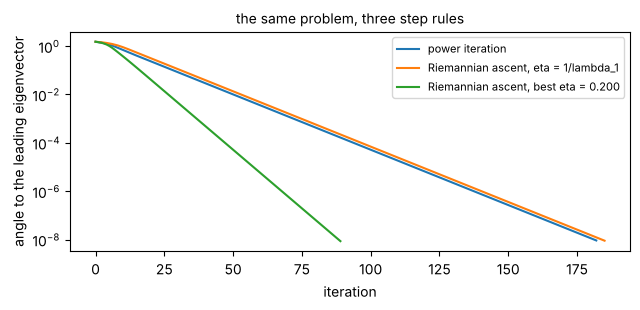

In [2]:
lam = np.linalg.eigvalsh(A)[::-1]
w_all, V_all = np.linalg.eigh(A); v1 = V_all[:, -1]
angle = lambda y: np.arctan2(np.linalg.norm(y - (y @ v1) * v1), abs(y @ v1))
x0 = rng.normal(size=n); x0 /= np.linalg.norm(x0)

def iterate(step, max_iter=5000, tol=1e-8):
    y, errs = x0.copy(), []
    for _ in range(max_iter):
        errs.append(angle(y))
        if errs[-1] < tol: break
        y = step(y)
    return np.array(errs)

eta_best = 2 / ((lam[0] - lam[1]) + (lam[0] - lam[-1]))
methods = {"power iteration": lambda y: A @ y / np.linalg.norm(A @ y),
           "Riemannian ascent, eta = 1/lambda_1": lambda y: retract(y, proj(y, A @ y) / lam[0]),
           f"Riemannian ascent, best eta = {eta_best:.3f}": lambda y: retract(y, eta_best * proj(y, A @ y))}
kappa = (lam[0] - lam[-1]) / (lam[0] - lam[1])
theory = [lam[1] / lam[0], lam[1] / lam[0], (kappa - 1) / (kappa + 1)]
curves = {}
for (name, step), rate in zip(methods.items(), theory):
    errs = iterate(step)
    curves[name] = errs
    measured = (errs[-1] / errs[-21]) ** (1 / 20)
    print(f"{name:38s}: {len(errs) - 1:4d} iterations; rate per iteration {measured:.4f} measured, {rate:.4f} predicted")

plt.figure(figsize=(6.5, 3.2))
for name, errs in curves.items():
    plt.semilogy(errs, label=name)
plt.xlabel("iteration"); plt.ylabel("angle to the leading eigenvector"); plt.legend(fontsize=8)
plt.title("the same problem, three step rules", fontsize=10); plt.tight_layout(); plt.show()

### 3. Orthonormal frames: the Stiefel manifold against a penalty
The top-$k$ principal subspace maximizes $\frac12\operatorname{tr}(X^\top A X)$ over $n \times k$ matrices with orthonormal columns, $X^\top X = I_k$: the **Stiefel manifold**. Its tangent space at $X$ is $\{V : X^\top V + V^\top X = 0\}$, the projection is $P_X(G) = G - X\,\operatorname{sym}(X^\top G)$ with $\operatorname{sym}(M) = (M + M^\top)/2$, and the **QR retraction** keeps the Q factor of $X + V$ (with a positive diagonal in R) (Absil et al. 2008; Boumal 2023).

The common alternative is a **penalty**: maximize $\frac12\operatorname{tr}(X^\top A X) - \frac\mu4\|X^\top X - I\|_F^2$ with plain gradient ascent. By hand, for one column $x$ in an eigenvector direction with eigenvalue $\lambda$, write $s = \|x\|^2$: the objective $\frac12\lambda s - \frac\mu4(s - 1)^2$ is largest at $s = 1 + \lambda/\mu$. So for $\lambda = 10$ and $\mu = 100$ the column has $\|x\|^2 = 1.1$: the constraint is never met exactly. Here $n = 20$, $k = 3$ and the top eigenvalues are 10, 8 and 6, so the true maximum is $\frac12(10 + 8 + 6) = 12$.

In [3]:
n2, k = 20, 3
lam2 = np.r_[10, 8, 6, 3, 2.5, np.linspace(2, 0.5, n2 - 5)]
Q2 = ortho_group.rvs(n2, random_state=2); A2 = (Q2 * lam2) @ Q2.T; top = Q2[:, :k]

def qf(M):                                        # QR retraction: Q factor with a positive diagonal in R
    Qm, Rm = np.linalg.qr(M); return Qm * np.sign(np.diag(Rm))

X = qf(rng.normal(size=(n2, k)))
for it in range(5000):
    G = A2 @ X
    grad = G - X @ ((X.T @ G + G.T @ X) / 2)      # Riemannian gradient on the Stiefel manifold
    if np.linalg.norm(grad) < 1e-10: break
    X = qf(X + grad / lam2[0])
print(f"Stiefel, QR retraction: {it} iterations, objective {0.5 * np.trace(X.T @ A2 @ X):.6f} (maximum 12), "
      f"||X^T X - I|| = {np.linalg.norm(X.T @ X - np.eye(k)):.1e}, largest angle to the true subspace {np.degrees(linalg.subspace_angles(X, top)).max():.1e} degrees")

for mu in [10, 100, 1000]:
    X = rng.normal(size=(n2, k)) * 0.3
    eta_p = 1 / (lam2[0] + 3 * mu)                  # a smaller step is needed as mu grows
    for it in range(200000):
        g = A2 @ X - mu * X @ (X.T @ X - np.eye(k))
        if np.linalg.norm(g) < 1e-8: break
        X = X + eta_p * g
    print(f"penalty mu = {mu:4d}: {it:6d} iterations, objective {0.5 * np.trace(X.T @ A2 @ X):.4f}, ||X^T X - I|| = {np.linalg.norm(X.T @ X - np.eye(k)):.4f} "
          f"(theory sqrt(10^2 + 8^2 + 6^2)/mu = {np.sqrt(200) / mu:.4f}), largest angle to the true subspace {np.degrees(linalg.subspace_angles(X, top)).max():.1e} degrees")

Stiefel, QR retraction: 67 iterations, objective 12.000000 (maximum 12), ||X^T X - I|| = 5.6e-16, largest angle to the true subspace 1.9e-09 degrees
penalty mu =   10:    270 iterations, objective 22.0000, ||X^T X - I|| = 1.4142 (theory sqrt(10^2 + 8^2 + 6^2)/mu = 1.4142), largest angle to the true subspace 1.4e-07 degrees
penalty mu =  100:   2180 iterations, objective 13.0000, ||X^T X - I|| = 0.1414 (theory sqrt(10^2 + 8^2 + 6^2)/mu = 0.1414), largest angle to the true subspace 1.9e-07 degrees


penalty mu = 1000:  20439 iterations, objective 12.1000, ||X^T X - I|| = 0.0141 (theory sqrt(10^2 + 8^2 + 6^2)/mu = 0.0141), largest angle to the true subspace 1.9e-07 degrees


### 4. Aligning two "languages": orthogonal Procrustes
Word vectors of two languages can often be aligned by a rotation (Conneau et al. 2018). Given a seed dictionary, columns $x_i$ (source words) and $y_i$ (their translations), the **orthogonal Procrustes** problem is $\min_{W^\top W = I}\|WX - Y\|_F^2$. Its solution is $W = UV^\top$ from the SVD $YX^\top = U\Sigma V^\top$ (Schönemann 1966). By hand: if $X = I_2$ and $Y = \begin{pmatrix} 0 & -1 \\ 1 & 0\end{pmatrix}$, then $YX^\top = Y$ is already a rotation and $W = Y$.

The data are **synthetic**: 2,000 "words" in $d = 20$ dimensions, and the second language is a random rotation of the first plus noise. Real data would be word vectors trained separately on Bangla and English text, with a bilingual dictionary. We compare least squares $W = YX^{+}$ (no constraint) with Procrustes for different dictionary sizes. **P@1** is the fraction of 500 held-out words whose translated vector has its true translation as nearest neighbour (by cosine similarity) among all 2,000 target words.

Then we solve the same problem by Riemannian gradient descent on the orthogonal group O(d). Its tangent vectors at $W$ are $W\Omega$ with $\Omega$ skew-symmetric, the Riemannian gradient is $W\operatorname{skew}(W^\top G)$ with $G = (WX - Y)X^\top$, and we retract with the **Cayley transform** $W \leftarrow W(I + \frac\eta2\Omega)^{-1}(I - \frac\eta2\Omega)$, $\Omega = \operatorname{skew}(W^\top G)$, which is orthogonal for every skew $\Omega$.

In [4]:
U2, _, Vt2 = np.linalg.svd(np.array([[0.0, -1.0], [1.0, 0.0]]) @ np.eye(2))
print("2-D by hand: Procrustes gives W =", ((U2 @ Vt2).round(6) + 0.0).tolist())
d, N = 20, 2000
Xall = (rng.normal(size=(N, d)) * np.linspace(2.0, 0.5, d)).T          # source vectors, d x N
W_true = ortho_group.rvs(d, random_state=3)
Yall = W_true @ Xall + 0.3 * rng.normal(size=(d, N))                   # target vectors: rotation plus noise
test = np.arange(N - 500, N)
Tn = Yall / np.linalg.norm(Yall, axis=0)

def p_at_1(W):
    P_ = W @ Xall[:, test]; P_ /= np.linalg.norm(P_, axis=0)
    return np.mean(np.argmax(Tn.T @ P_, axis=0) == test)

def procrustes(X_, Y_):
    U, _, Vt = np.linalg.svd(Y_ @ X_.T); return U @ Vt

print(f"true rotation: P@1 {p_at_1(W_true):.3f}")
print("pairs | least squares: error, P@1 | Procrustes: error, P@1     (error = ||W - W_true||_F / sqrt(d))")
for npairs in [10, 20, 40, 100, 400]:
    X_, Y_ = Xall[:, :npairs], Yall[:, :npairs]
    W_ls, W_pr = Y_ @ np.linalg.pinv(X_), procrustes(X_, Y_)
    print(f"{npairs:5d} | {np.linalg.norm(W_ls - W_true) / np.sqrt(d):13.3f}, {p_at_1(W_ls):.3f} | {np.linalg.norm(W_pr - W_true) / np.sqrt(d):10.3f}, {p_at_1(W_pr):.3f}")

X_, Y_ = Xall[:, :100], Yall[:, :100]
W_svd = procrustes(X_, Y_); f = lambda W: 0.5 * np.linalg.norm(W @ X_ - Y_) ** 2; f_star = f(W_svd)
eta_o = 1 / np.linalg.svd(Y_ @ X_.T, compute_uv=False)[0]              # step 1 / (largest singular value of Y X^T)
W, gaps, I_d = np.eye(d), [], np.eye(d)
for it in range(3000):
    gaps.append(f(W) - f_star)
    if gaps[-1] < 1e-9 * f_star: break
    Om = W.T @ ((W @ X_ - Y_) @ X_.T); Om = (Om - Om.T) / 2                 # skew(W^T G)
    W = W @ np.linalg.solve(I_d + eta_o / 2 * Om, I_d - eta_o / 2 * Om)      # Cayley retraction of the step -eta W Omega
print(f"Riemannian gradient descent on O(20), 100 pairs: {it} iterations, f - f* = {gaps[-1]:.1e}, ||W - W_svd|| = {np.linalg.norm(W - W_svd):.1e}, "
      f"||W^T W - I|| = {np.linalg.norm(W.T @ W - I_d):.1e}, error vs W_true {np.linalg.norm(W - W_true) / np.sqrt(d):.3f}")

2-D by hand: Procrustes gives W = [[0.0, -1.0], [1.0, 0.0]]
true rotation: P@1 1.000
pairs | least squares: error, P@1 | Procrustes: error, P@1     (error = ||W - W_true||_F / sqrt(d))


   10 |         0.743, 0.454 |      1.061, 0.194
   20 |         6.700, 0.148 |      0.603, 0.968


   40 |         0.373, 1.000 |      0.170, 1.000
  100 |         0.162, 1.000 |      0.080, 1.000
  400 |         0.068, 1.000 |      0.038, 1.000


Riemannian gradient descent on O(20), 100 pairs: 372 iterations, f - f* = 7.5e-08, ||W - W_svd|| = 8.7e-05, ||W^T W - I|| = 4.9e-14, error vs W_true 0.080


### 5. Momentum and Adam need the Riemannian gradient
A tempting shortcut: run an ordinary optimizer on the Euclidean gradient, then normalize after each step. For plain gradient descent this is fine (section 1: only the step size changes). For momentum and Adam it is not, because their states accumulate the radial part of the gradient. We maximize the Rayleigh quotient of a $100 \times 100$ matrix with eigenvalues evenly spaced from 1 to 10, for 300 steps, with seven methods. To be fair, each method gets its best learning rate from the same grid. The Riemannian versions project the gradient onto the tangent space, keep the momentum tangent by projecting it onto the new tangent space (a simple **vector transport**), and, for Riemannian Adam, use one second-moment number per point, the squared norm of the Riemannian gradient, as in Bécigneul & Ganea 2019 and geoopt.

angle to the leading eigenvector after 300 steps (radians), best learning rate from [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]:
  Riemannian GD                              : best 5.7e-02 at lr = 0.1
  Riemannian heavy ball                      : best 1.1e-07 at lr = 0.3
  heavy ball, no transport                   : best 7.0e-08 at lr = 0.3
  SGD momentum, then normalize               : best 8.6e-01 at lr = 1.0
  Riemannian Adam                            : best 2.9e-07 at lr = 1.0
  Adam on projected gradient, then normalize : best 7.2e-07 at lr = 0.03
  Adam, then normalize                       : best 1.3e+00 at lr = 0.003


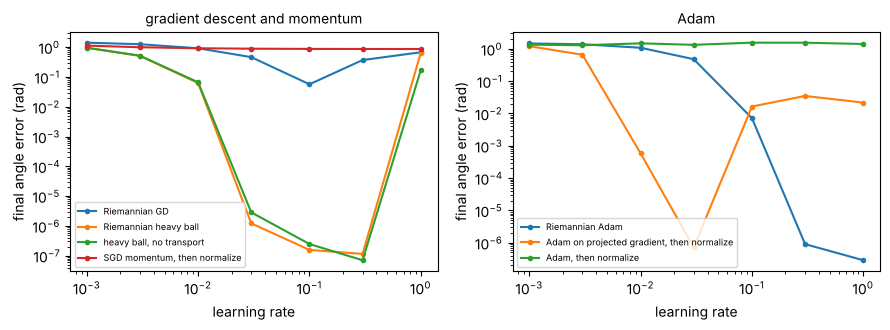

runtime so far 9.0 s


In [5]:
n3, steps = 100, 300
lam3 = np.linspace(1, 10, n3); Q3 = ortho_group.rvs(n3, random_state=4)
A_t = torch.tensor((Q3 * lam3) @ Q3.T); v_top = torch.tensor(Q3[:, -1])
x_init = torch.randn(n3, dtype=torch.float64); x_init /= x_init.norm()
tproj = lambda x, u: u - (x @ u) * x
loss_fn = lambda x: -0.5 * x @ A_t @ x                                  # minimize the negative Rayleigh quotient
def angle_t(x): return float(torch.atan2(torch.linalg.norm(x - (x @ v_top) * v_top), torch.abs(x @ v_top)))

def run(method, lr, beta=0.9, b1=0.9, b2=0.999, eps=1e-8):
    x = x_init.clone().requires_grad_(True)
    if method in ("SGD momentum, then normalize", "Adam, then normalize", "Adam on projected gradient, then normalize"):
        opt = torch.optim.SGD([x], lr=lr, momentum=beta) if method.startswith("SGD") else torch.optim.Adam([x], lr=lr)
        for _ in range(steps):
            opt.zero_grad(); loss_fn(x).backward()
            if method.startswith("Adam on projected"):
                with torch.no_grad(): x.grad.copy_(tproj(x, x.grad))
            opt.step()
            with torch.no_grad(): x /= x.norm()                         # normalize after the ordinary step
        return angle_t(x.detach())
    x = x.detach(); m = torch.zeros_like(x); v = torch.zeros((), dtype=torch.float64)
    for t in range(1, steps + 1):
        xr = x.clone().requires_grad_(True); loss_fn(xr).backward()
        g = tproj(x, xr.grad)                                           # Riemannian gradient
        if method == "Riemannian GD":
            step = -lr * g
        elif method == "Riemannian heavy ball":
            m = beta * m - lr * g; step = m
        elif method == "heavy ball, no transport":
            m = beta * m - lr * g; step = m
        else:                                                           # Riemannian Adam
            m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * (g @ g)
            step = -lr * (m / (1 - b1 ** t)) / (torch.sqrt(v / (1 - b2 ** t)) + eps)
        x_new = (x + step) / (x + step).norm()                          # retraction
        if method in ("Riemannian heavy ball", "Riemannian Adam"):
            m = tproj(x_new, m)                                         # transport: project onto the new tangent space
        x = x_new
    return angle_t(x)

lrs = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
names = ["Riemannian GD", "Riemannian heavy ball", "heavy ball, no transport", "SGD momentum, then normalize",
         "Riemannian Adam", "Adam on projected gradient, then normalize", "Adam, then normalize"]
table = {name: [run(name, lr) for lr in lrs] for name in names}
print(f"angle to the leading eigenvector after {steps} steps (radians), best learning rate from {lrs}:")
for name, errs in table.items():
    i = int(np.argmin(errs))
    print(f"  {name:43s}: best {errs[i]:.1e} at lr = {lrs[i]}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for name, errs in table.items():
    a_ = ax[1] if "Adam" in name else ax[0]
    a_.loglog(lrs, errs, "o-", ms=3, label=name)
for a_, title in zip(ax, ["gradient descent and momentum", "Adam"]):
    a_.set_xlabel("learning rate"); a_.set_ylabel("final angle error (rad)"); a_.set_title(title, fontsize=10); a_.legend(fontsize=6.5)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.1f} s")

### 6. The same with geoopt
geoopt wraps a tensor as a `ManifoldParameter` on a manifold, and `RiemannianAdam` does what section 5 did by hand: Riemannian gradient, transported momentum, one second moment per point (Kochurov et al. 2020). geoopt is not installed here, so this cell is NOT RUN (in Colab or Kaggle, run `pip install geoopt` first).

In [ ]:
# NOT RUN: needs geoopt (pip install geoopt), which is not installed here
import torch
import geoopt
from scipy.stats import ortho_group

torch.manual_seed(0)
n, k = 20, 3
Q = torch.tensor(ortho_group.rvs(n, random_state=2))
lam = torch.cat([torch.tensor([10.0, 8, 6, 3, 2.5]), torch.linspace(2, 0.5, n - 5)]).double()
A = Q @ torch.diag(lam) @ Q.T
X = geoopt.ManifoldParameter(torch.linalg.qr(torch.randn(n, k, dtype=torch.float64))[0],
                             manifold=geoopt.EuclideanStiefel())        # n x k matrices with orthonormal columns
opt = geoopt.optim.RiemannianAdam([X], lr=0.05)
for step in range(500):
    opt.zero_grad()
    loss = -0.5 * torch.trace(X.T @ A @ X)                              # maximize the Rayleigh quotient
    loss.backward()
    opt.step()                                                          # Riemannian gradient, retraction, transported momentum
print(f"objective {-loss.item():.4f} (maximum 12), ||X^T X - I|| = {torch.linalg.norm(X.T @ X - torch.eye(k, dtype=torch.float64)):.1e}")

### 7. Exercises

In [6]:
# TODO: compare retractions on O(d). Repeat the Riemannian gradient descent of section 4 (100 pairs) three ways: the
# Cayley transform used above, the exponential map W @ scipy.linalg.expm(-eta * Om), and the QR retraction qf(W - eta * W @ Om).
# Return the number of iterations each needs to reach f - f* < 1e-9 f*, and the time each takes. Do they find the same W?
def compare_retractions():
    return None          # replace with your code

r = compare_retractions()
print("not done yet" if r is None else r)

not done yet


In [7]:
# TODO: Riemannian SGD (Bonnabel 2013). Solve the 400-pair Procrustes problem with minibatches of 32 random pairs: at step t
# use only the minibatch to form G, take the Cayley step with eta_t = eta0 / (1 + t / 100), and run 2,000 steps. Plot the
# error ||W - W_true||_F / sqrt(d) against the step and compare with the SVD solution. Return the final error.
def riemannian_sgd_procrustes():
    return None          # replace with your code

r = riemannian_sgd_procrustes()
print("not done yet" if r is None else f"final error {r:.3f}")

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **The Riemannian gradient is the projected gradient.** The hand example gave $(1, -1, 0)/\sqrt2$, perpendicular to $x$, and a finite difference along a retraction curve matched $\langle\operatorname{grad} f, v\rangle$ (5.90023477 both ways). Power iteration is a Riemannian step with $\eta = 1/(x^\top Ax)$, and normalizing a Euclidean step is a Riemannian step with $\eta/(1 + \eta\,x^\top Ax)$: both identities held to 5.6e-17.
2. **The step size decides the speed, as theory predicts.** Power iteration needed 182 iterations and Riemannian ascent with $\eta = 1/\lambda_1$ needed 185 (both shrink the error by 0.9000 per iteration); the best fixed step, $\eta = 0.200$, needed 89 (0.8000 per iteration). Measured and predicted rates agreed to four decimals.
3. **A penalty never meets the constraint.** The QR retraction reached the maximum 12.000000 in 67 iterations with $\|X^\top X - I\|$ = 5.6e-16. The penalty method found the right subspace (angles near 1e-7 degrees) but with stretched columns: objective 22.0000, 13.0000 and 12.1000 and orthogonality error 1.4142, 0.1414 and 0.0141 for $\mu$ = 10, 100 and 1000, exactly $\sqrt{10^2 + 8^2 + 6^2}/\mu$ from the hand calculation, while the iterations grew from 270 to 20,439.
4. **Procrustes needs enough pairs; against expectation, least squares won with very few.** With 10 pairs (fewer than the 20 dimensions), least squares reached P@1 0.454 and Procrustes only 0.194: the rotation is undetermined in directions the dictionary does not cover, and Procrustes fills them arbitrarily. With 20 pairs least squares collapsed (error 6.700, P@1 0.148) while Procrustes reached 0.968. From 40 pairs on both reached P@1 1.000, and the Procrustes error was about half the least-squares error (0.080 against 0.162 with 100 pairs). Riemannian gradient descent with the Cayley retraction reached the SVD solution (difference 8.7e-05) in 372 iterations and stayed orthogonal to 4.9e-14.
5. **Momentum and Adam fail on the raw Euclidean gradient.** With each method's best learning rate, SGD with momentum followed by normalization ended 0.86 rad from the answer, and Adam followed by normalization 1.3 rad: neither converged at any learning rate in the grid. Projecting the gradient first fixed both: Riemannian heavy ball 1.1e-07, Riemannian Adam 2.9e-07, Adam on the projected gradient 7.2e-07. Plain Riemannian gradient descent was slow on this badly conditioned problem (5.7e-02).
6. **Transporting the momentum made no measurable difference here**, against what one might expect: the heavy ball without transport ended at 7.0e-08, as good as with it. On the sphere with small steps, the retraction removes most of the non-tangent part of the old momentum. Riemannian Adam (Bécigneul & Ganea 2019) and geoopt transport it anyway, so that the momentum is always a tangent vector at the current point.
